# 05 — Performance Evaluation

Continue from the stabilized baseline. The existing 24,004/5,996 partition and
both fitted baseline pipelines are fixed. The holdout is locked for development
decisions; its earlier baseline-stage inspection is disclosed. No tuning,
preprocessing change, resplit, calibration fitting or new threshold is performed.
ID and SEX remain metadata. Formal fairness and all later stages remain deferred.

Run `python script_performance_evaluation.py` in the pinned environment to generate
results. This notebook verifies and displays the saved stage artifacts, without
refitting models. The script resolves paths from its location; this notebook finds
the project from the current directory or its parents.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/performance_evaluation.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.baseline import sha256
from src.performance_evaluation import TABLE_DIR, FIGURE_DIR, METRICS

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)
manifest = json.loads((TABLE_DIR / "run_manifest.json").read_text())
for category in ("locked_input_hashes", "output_hashes", "source_hashes"):
    for name, expected in manifest[category].items():
        assert sha256(ROOT / name) == expected, f"Changed artifact: {name}"
def read_table(name):
    return pd.read_csv(TABLE_DIR / f"{name}.csv", float_precision="round_trip")
print("Verified locked inputs, evaluation sources and result CSV hashes.")
print("CV:", manifest["cv"])
print("Bootstrap:", manifest["bootstrap"])


Verified locked inputs, evaluation sources and result CSV hashes.
CV: {'splitter': 'StratifiedGroupKFold', 'n_splits': 5, 'shuffle': True, 'random_state': 42, 'std_ddof': 1, 'preprocessing_fit_within_each_fold': True}
Bootstrap: {'unit': 'exact predictor group', 'repetitions': 2000, 'random_seed': 42, 'interval': '2.5th and 97.5th percentiles, linear quantiles', 'models_refitted': False, 'same_resamples_for_both_models': True, 'model_difference_test': False}


## Training-only group-aware cross-validation

Five-fold StratifiedGroupKFold, shuffled with seed 42, uses groups defined by exact
equality of the 22 model predictors (excluding ID, SEX, target). The same folds
serve both models. Each temporary model fits its entire preprocessing pipeline
inside the fold, with unchanged baseline hyperparameters. No fold model overwrites
the fitted baseline artifacts. Fold summary SD uses ddof=1; it is not a CI.

In [2]:
folds = read_table("cv_fold_metrics")
display(read_table("cv_partition_summary"))
display(folds[["model", "fold", *METRICS]])
summary = read_table("cv_summary_metrics")
display(summary.pivot(index="metric", columns="model", values=["mean", "std", "minimum", "maximum"]))
ranking = folds.pivot(index="fold", columns="model", values=["ROC-AUC", "Average Precision (AP)"])
for metric in ["ROC-AUC", "Average Precision (AP)"]:
    wins = (ranking[metric]["gradient_boosting"] > ranking[metric]["logistic"]).sum()
    print(f"Boosting higher {metric}: {wins}/5 folds (descriptive only).")


,fold,fit_records,validation_records,fit_groups,validation_groups,fit_default_rate,validation_default_rate,crossing_groups
0,1,19203,4801,19147,4783,0.221476,0.221412,0
1,2,19203,4801,19144,4786,0.221476,0.221412,0
2,3,19202,4802,19141,4789,0.221435,0.221574,0
3,4,19204,4800,19144,4786,0.221464,0.221458,0
4,5,19204,4800,19144,4786,0.221464,0.221458,0


,model,fold,ROC-AUC,Average Precision (AP),Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,Log Loss,Brier Score
0,logistic,1,0.773975,0.538336,0.822537,0.658153,0.688057,0.363123,0.953184,0.475369,0.435218,0.136260
1,logistic,2,0.769736,0.548768,0.822120,0.652837,0.696060,0.349012,0.956661,0.464912,0.436735,0.136274
2,logistic,3,0.765807,0.545195,0.821949,0.660068,0.681109,0.369361,0.950776,0.478976,0.437496,0.136049
3,logistic,4,0.766945,0.549353,0.820208,0.654656,0.678571,0.357479,0.951833,0.468269,0.434327,0.135777
4,logistic,5,0.769052,0.544516,0.815625,0.647000,0.660650,0.344309,0.949692,0.452690,0.437667,0.136698
5,gradient_boosting,1,0.786074,0.554548,0.823787,0.660639,0.692035,0.367827,0.953451,0.480344,0.427711,0.134388
6,gradient_boosting,2,0.787396,0.564888,0.818996,0.647801,0.683019,0.340546,0.955056,0.454488,0.425532,0.133302
7,gradient_boosting,3,0.781616,0.555411,0.824865,0.666311,0.689304,0.381579,0.951043,0.491228,0.426147,0.132952
8,gradient_boosting,4,0.785626,0.551186,0.821042,0.656537,0.680851,0.361242,0.951833,0.472034,0.427253,0.134106
9,gradient_boosting,5,0.778613,0.553132,0.815208,0.648416,0.655477,0.349012,0.947819,0.455494,0.429930,0.134579


mean                         std  \
model                  gradient_boosting  logistic gradient_boosting   
metric                                                                 
Accuracy                        0.820779  0.820488          0.003874   
Average Precision (AP)          0.555833  0.545234          0.005308   
Balanced Accuracy               0.655941  0.654543          0.007951   
Brier Score                     0.133865  0.136212          0.000706   
F1                              0.470718  0.468043          0.015892   
Log Loss                        0.427315  0.436289          0.001699   
Precision                       0.680137  0.680890          0.014513   
ROC-AUC                         0.783865  0.769103          0.003643   
Recall                          0.360041  0.356657          0.016028   
Specificity                     0.951841  0.952429          0.002727   

                                           minimum            \
model                   logistic gradient_boosting  logistic   
metric                                                         
Accuracy                0.002860          0.815208  0.815625   
Average Precision (AP)  0.004403          0.551186  0.538336   
Balanced Accuracy       0.005084          0.647801  0.647000   
Brier Score             0.000338          0.132952  0.135777   
F1                      0.010232          0.454488  0.452690   
Log Loss                0.001462          0.425532  0.434327   
Precision               0.013196          0.655477  0.660650   
ROC-AUC                 0.003149          0.778613  0.765807   
Recall                  0.010183          0.340546  0.344309   
Specificity             0.002695          0.947819  0.949692   

                                 maximum            
model                  gradient_boosting  logistic  
metric                                              
Accuracy                        0.824865  0.822537  
Average Precision (AP)          0.564888  0.549353  
Balanced Accuracy               0.666311  0.660068  
Brier Score                     0.134579  0.136698  
F1                              0.491228  0.478976  
Log Loss                        0.429930  0.437667  
Precision                       0.692035  0.696060  
ROC-AUC                         0.787396  0.773975  
Recall                          0.381579  0.369361  
Specificity                     0.955056  0.956661

Boosting higher ROC-AUC: 5/5 folds (descriptive only).
Boosting higher Average Precision (AP): 5/5 folds (descriptive only).


Boosting leads ROC-AUC and AP in all five folds. Recall and precision vary more
across folds than accuracy or probability losses. Differences are descriptive;
neither five-fold SD nor marginal holdout CIs provide a significance test.
Both models remain in the research design.

One OOF prediction per training ID per model; no holdout IDs or crossing groups.


,ID,SEX,actual,duplicate_group_id,model,partition,fold,probability_default,predicted
0,22789,2,0,22789,logistic,training_oof,1,0.720992,1
1,29007,2,0,29007,logistic,training_oof,2,0.284788,0
2,16951,1,0,16951,logistic,training_oof,2,0.366802,0
3,22281,2,1,22281,logistic,training_oof,4,0.123477,0
4,11347,2,0,11347,logistic,training_oof,1,0.259095,0
24004,22789,2,0,22789,gradient_boosting,training_oof,1,0.771465,1
24005,29007,2,0,29007,gradient_boosting,training_oof,2,0.294755,0
24006,16951,1,0,16951,gradient_boosting,training_oof,2,0.381161,0
24007,22281,2,1,22281,gradient_boosting,training_oof,4,0.087649,0
24008,11347,2,0,11347,gradient_boosting,training_oof,1,0.330884,0


,model,partition,threshold,records,TN,FP,FN,TP,Predicted-positive Rate,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,FPR,FNR,F1,ROC-AUC,Average Precision (AP),Log Loss,Brier Score
0,logistic,training_oof,0.5,24004,17799.0,889.0,3420.0,1896.0,0.116022,0.820488,0.654544,0.680790,0.356659,0.952429,0.047571,0.643341,0.468090,0.769080,0.544622,0.436289,0.136212
1,gradient_boosting,training_oof,0.5,24004,17788.0,900.0,3402.0,1914.0,0.117230,0.820780,0.655943,0.680171,0.360045,0.951841,0.048159,0.639955,0.470849,0.783748,0.555253,0.427314,0.133865


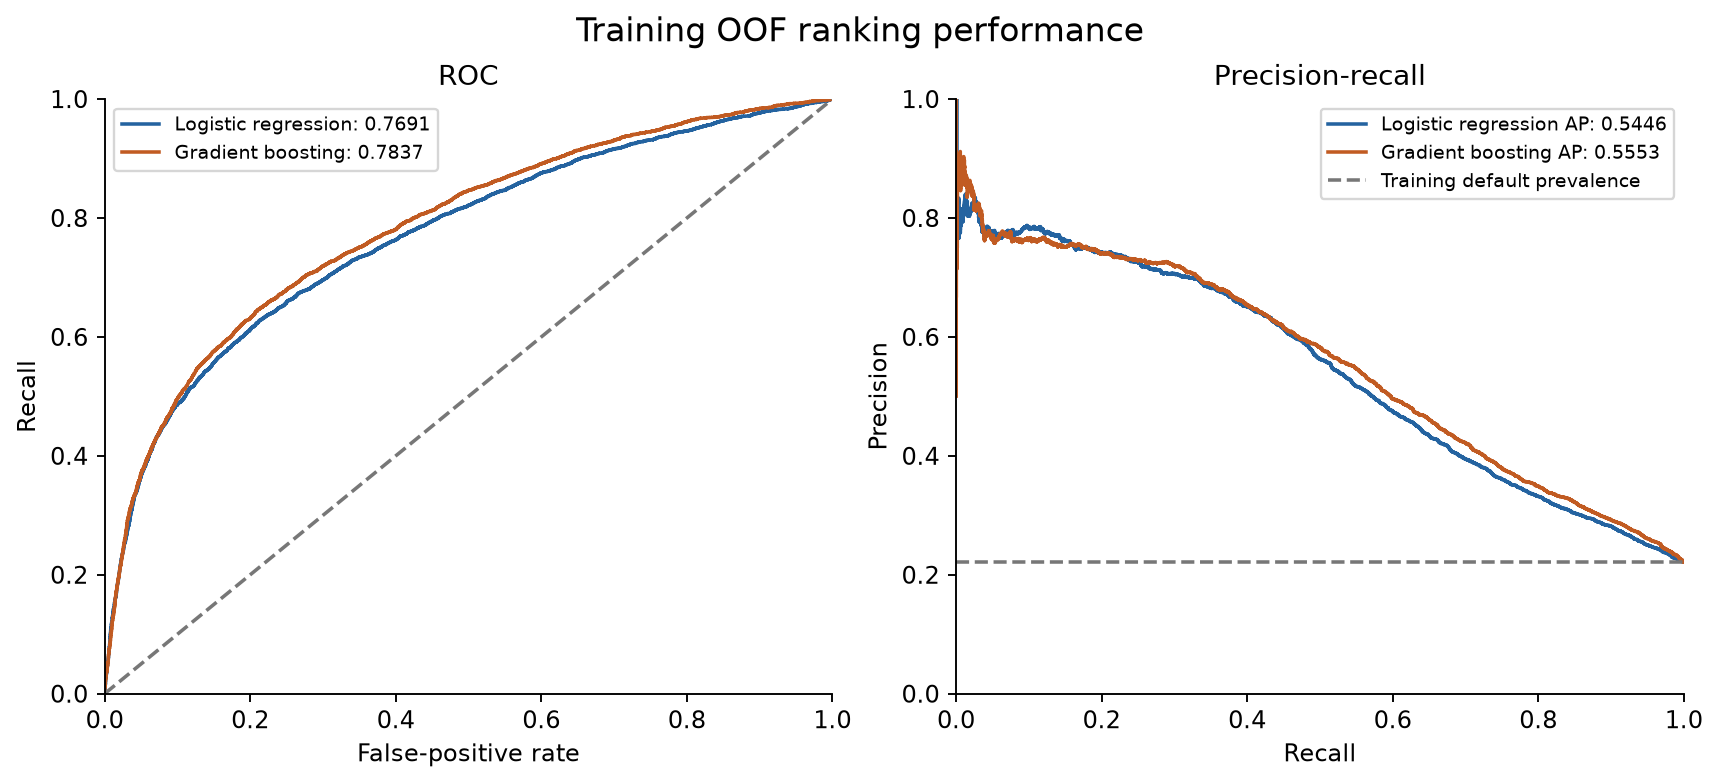

In [3]:
oof = read_table("oof_predictions")
training = pd.read_csv(ROOT / "data/processed/train_metadata.csv")
holdout_ids = set(pd.read_csv(ROOT / "data/processed/test_metadata.csv").ID)
for model, part in oof.groupby("model"):
    assert part.ID.is_unique and len(part) == len(training)
    np.testing.assert_array_equal(part.ID, training.ID)
    np.testing.assert_array_equal(part.SEX, training.SEX)
    np.testing.assert_array_equal(part.actual, training.default)
    assert not set(part.ID) & holdout_ids
    assert part.groupby("duplicate_group_id").fold.nunique().eq(1).all()
print("One OOF prediction per training ID per model; no holdout IDs or crossing groups.")
display(oof.groupby("model", sort=False).head(5))
display(read_table("oof_metrics"))
display(Image(filename=str(FIGURE_DIR / "oof_roc_precision_recall.png")))


## OOF threshold trade-offs — candidates only

The grid uses 0.00–1.00 in 0.01 steps. Class 1 means probability > threshold;
exact ties are class 0, consistent with the fixed baselines at 0.50. Precision/F1
are zero when no cases are predicted positive. Threshold analysis has no holdout
inputs. The 0.50 operating point remains in force.

For each target, the candidate is the greatest representable float below the score
of the ceil(target × positive count)th highest OOF positive case. All ties are
included, so recall may exceed the target. CSVs are read with round-trip float
precision because rounding a threshold at a score boundary can change a decision.
Candidates are not thresholds selected for future use or validated on holdout.

**Existing 0.50 — OOF training predictions**

,model,partition,threshold,TN,FP,FN,TP,Predicted-positive Rate,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,FPR,FNR,F1
50,logistic,training_oof,0.5,17799.0,889.0,3420.0,1896.0,0.116022,0.820488,0.654544,0.680790,0.356659,0.952429,0.047571,0.643341,0.468090
151,gradient_boosting,training_oof,0.5,17788.0,900.0,3402.0,1914.0,0.117230,0.820780,0.655943,0.680171,0.360045,0.951841,0.048159,0.639955,0.470849


**Selected grid rows; the CSV contains all 101 thresholds per model**

,model,partition,threshold,TN,FP,FN,TP,Predicted-positive Rate,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,FPR,FNR,F1
20,logistic,training_oof,0.2,14889.0,3799.0,2039.0,3277.0,0.294784,0.756791,0.706578,0.463115,0.616441,0.796714,0.203286,0.383559,0.528890
30,logistic,training_oof,0.3,16686.0,2002.0,2687.0,2629.0,0.192926,0.804658,0.693709,0.567696,0.494545,0.892872,0.107128,0.505455,0.528602
40,logistic,training_oof,0.4,17494.0,1194.0,3144.0,2172.0,0.140227,0.819280,0.672343,0.645276,0.408578,0.936109,0.063891,0.591422,0.500346
50,logistic,training_oof,0.5,17799.0,889.0,3420.0,1896.0,0.116022,0.820488,0.654544,0.680790,0.356659,0.952429,0.047571,0.643341,0.468090
121,gradient_boosting,training_oof,0.2,14258.0,4430.0,1768.0,3548.0,0.332361,0.741793,0.715184,0.444723,0.667419,0.762949,0.237051,0.332581,0.533775
131,gradient_boosting,training_oof,0.3,16452.0,2236.0,2492.0,2824.0,0.210798,0.803033,0.705789,0.558103,0.531226,0.880351,0.119649,0.468774,0.544333
141,gradient_boosting,training_oof,0.4,17399.0,1289.0,3054.0,2262.0,0.147934,0.819072,0.678267,0.637004,0.425508,0.931025,0.068975,0.574492,0.510206
151,gradient_boosting,training_oof,0.5,17788.0,900.0,3402.0,1914.0,0.117230,0.820780,0.655943,0.680171,0.360045,0.951841,0.048159,0.639955,0.470849


,model,recall_target,threshold,Recall,Precision,Specificity,FPR,Predicted-positive Rate,status
0,logistic,0.4,0.413695,0.400113,0.651056,0.938998,0.061002,0.136102,candidate_only
1,logistic,0.5,0.295040,0.500000,0.563374,0.889769,0.110231,0.196551,candidate_only
2,logistic,0.6,0.208703,0.600075,0.474632,0.811055,0.188945,0.279995,candidate_only
3,logistic,0.7,0.165241,0.700150,0.394196,0.693921,0.306079,0.393351,candidate_only
4,gradient_boosting,0.4,0.436154,0.400113,0.654059,0.939801,0.060199,0.135477,candidate_only
5,gradient_boosting,0.5,0.322791,0.500000,0.582129,0.897902,0.102098,0.190218,candidate_only
6,gradient_boosting,0.6,0.240803,0.600075,0.496112,0.826627,0.173373,0.267872,candidate_only
7,gradient_boosting,0.7,0.184185,0.700150,0.421852,0.727044,0.272956,0.367564,candidate_only


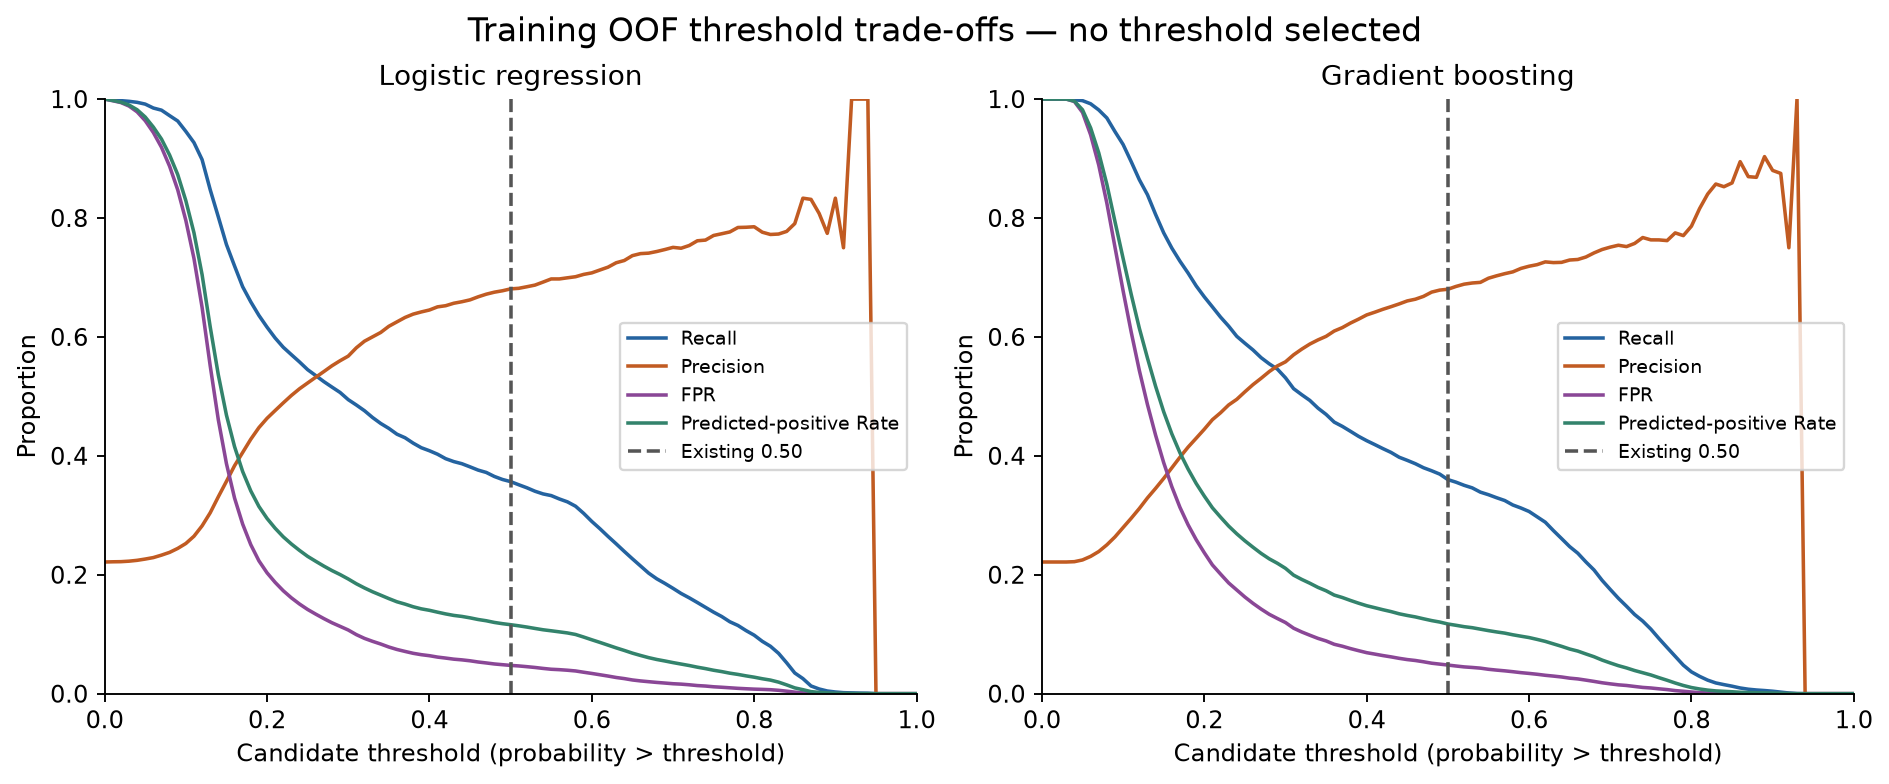

In [4]:
thresholds = read_table("threshold_tradeoffs")
assert set(thresholds.partition) == {"training_oof"}
display(Markdown("**Existing 0.50 — OOF training predictions**"))
display(thresholds[thresholds.threshold == .50])
display(Markdown("**Selected grid rows; the CSV contains all 101 thresholds per model**"))
display(thresholds[thresholds.threshold.round(2).isin([.50, .40, .30, .20])])
candidates = read_table("recall_target_candidates")
display(candidates[["model", "recall_target", "threshold", "Recall", "Precision", "Specificity", "FPR", "Predicted-positive Rate", "status"]])
display(Image(filename=str(FIGURE_DIR / "oof_threshold_tradeoffs.png")))


Lower thresholds gain recall at the cost of more false positives and more
flagged records. At roughly 60% OOF recall, logistic needs a threshold near 0.209
and boosting near 0.241; their FPRs are about 18.9% and 17.3%, respectively.
An operating objective and training-only validation protocol remain to be agreed.

## Calibration assessment — no calibration fitting

Reliability uses ten equal-width bins over [0,1], left-closed/right-open with 1
included in the final bin. Empty bins are retained in data and excluded from plotted
means. ECE = sum(count/N × absolute(mean probability − observed frequency)).
This ECE depends on binning. Brier score is mean((p-y)^2); log loss uses natural logs
with sklearn numerical clipping. These losses also reflect discrimination and are
not pure measures of calibration. Bin counts show where estimates are sparse.
[Calibration documentation](https://scikit-learn.org/stable/modules/calibration.html).

,model,partition,records,mean_probability,observed_frequency,Brier Score,Log Loss,ECE_10_uniform_bins
0,logistic,training_oof,24004,0.221384,0.221463,0.136212,0.436289,0.009842
1,gradient_boosting,training_oof,24004,0.221446,0.221463,0.133865,0.427314,0.010100
2,logistic,locked_holdout,5996,0.221535,0.220147,0.138169,0.440924,0.014031
3,gradient_boosting,locked_holdout,5996,0.222007,0.220147,0.134985,0.430067,0.010662


,partition,model,bin,lower,upper,count,mean_probability,observed_frequency,absolute_gap,ece_contribution
0,training_oof,logistic,1,0.0,0.1,4102,0.071678,0.070453,0.001224,0.000209
1,training_oof,logistic,2,0.1,0.2,12826,0.140435,0.136442,0.003994,0.002134
2,training_oof,logistic,3,0.2,0.3,2445,0.241575,0.265031,0.023456,0.002389
3,training_oof,logistic,4,0.3,0.4,1265,0.341453,0.361265,0.019812,0.001044
4,training_oof,logistic,5,0.4,0.5,581,0.446903,0.475043,0.028140,0.000681
5,training_oof,logistic,6,0.5,0.6,609,0.557833,0.584565,0.026732,0.000678
6,training_oof,logistic,7,0.6,0.7,921,0.644913,0.649294,0.004381,0.000168
7,training_oof,logistic,8,0.7,0.8,589,0.748826,0.711375,0.037451,0.000919
8,training_oof,logistic,9,0.8,0.9,648,0.841550,0.783951,0.057600,0.001555
9,training_oof,logistic,10,0.9,1.0,18,0.919244,0.833333,0.085911,0.000064


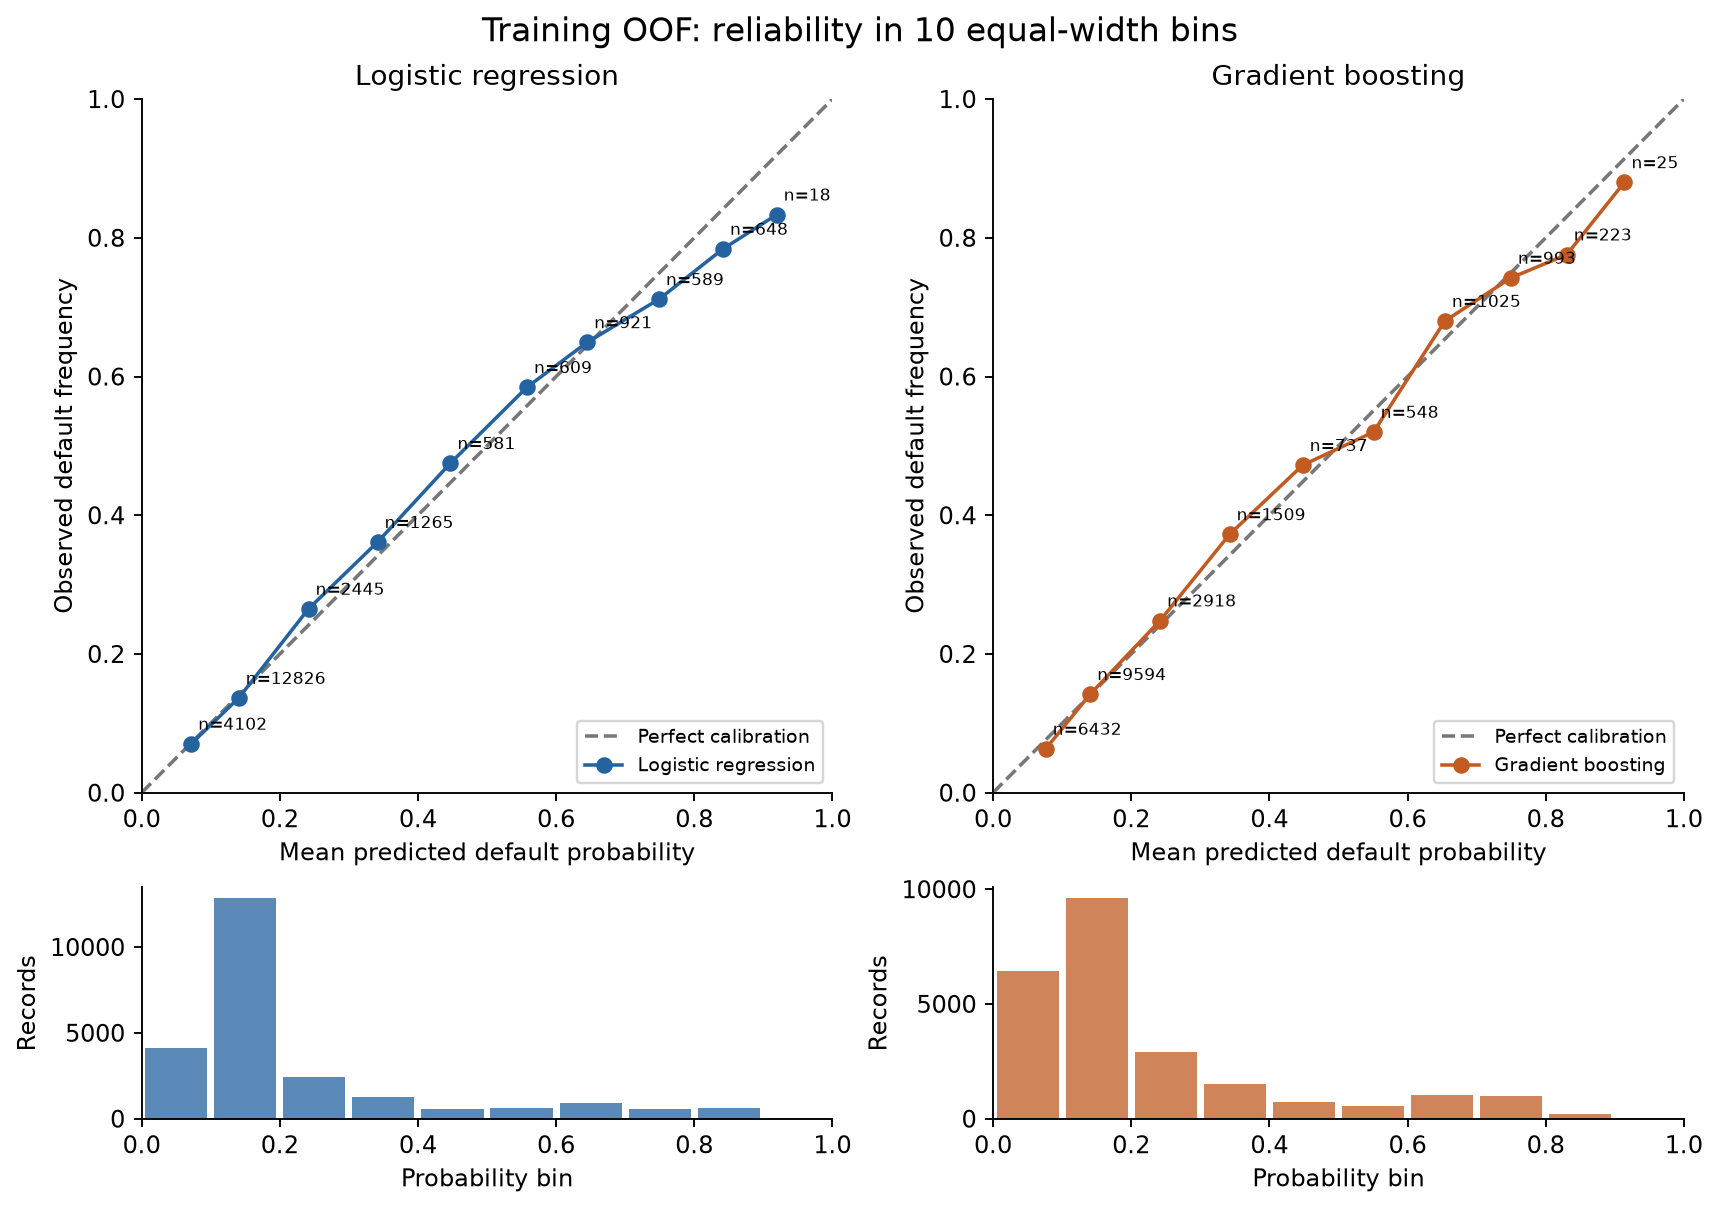

In [5]:
calibration = read_table("calibration_summary")
display(calibration)
bins = read_table("calibration_bins")
display(bins[bins.partition == "training_oof"])
display(Image(filename=str(FIGURE_DIR / "calibration_training_oof.png")))


At this bin resolution, OOF calibration broadly follows the diagonal for both
models. OOF ECE is about 0.0098 for logistic and 0.0101 for boosting, despite boosting's
lower Brier score/log loss. Similar global means do not guarantee calibration at
every risk level; sparse high-risk bins are particularly uncertain. There is no
pre-specified calibration pass/fail tolerance and no calibrator has been fitted.

## Locked holdout — existing fitted models, threshold 0.50 only

These predictions reproduce the stabilized model files and prediction CSVs.
The confusion matrix layout is [[TN, FP], [FN, TP]], with rows actual [0,1] and
columns predicted [0,1]. Average Precision (AP) is sklearn average precision,
not trapezoidal PR-AUC. Both models remain available for later comparison.

,model,threshold,records,TN,FP,FN,TP,ROC-AUC,Average Precision (AP),Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,Log Loss,Brier Score
0,logistic,0.5,5996,4437.0,239.0,852.0,468.0,0.756949,0.527009,0.818045,0.651717,0.661952,0.354545,0.948888,0.461766,0.440924,0.138169
1,gradient_boosting,0.5,5996,4439.0,237.0,856.0,464.0,0.778132,0.552136,0.817712,0.650415,0.661912,0.351515,0.949316,0.459179,0.430067,0.134985


,model,partition,threshold,records,TN,FP,FN,TP,Predicted-positive Rate,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,FPR,FNR,F1,ROC-AUC,Average Precision (AP),Log Loss,Brier Score
0,logistic,training_oof,0.5,24004,17799.0,889.0,3420.0,1896.0,0.116022,0.820488,0.654544,0.680790,0.356659,0.952429,0.047571,0.643341,0.468090,0.769080,0.544622,0.436289,0.136212
1,gradient_boosting,training_oof,0.5,24004,17788.0,900.0,3402.0,1914.0,0.117230,0.820780,0.655943,0.680171,0.360045,0.951841,0.048159,0.639955,0.470849,0.783748,0.555253,0.427314,0.133865
2,logistic,locked_holdout,0.5,5996,4437.0,239.0,852.0,468.0,0.117912,0.818045,0.651717,0.661952,0.354545,0.948888,0.051112,0.645455,0.461766,0.756949,0.527009,0.440924,0.138169
3,gradient_boosting,locked_holdout,0.5,5996,4439.0,237.0,856.0,464.0,0.116911,0.817712,0.650415,0.661912,0.351515,0.949316,0.050684,0.648485,0.459179,0.778132,0.552136,0.430067,0.134985


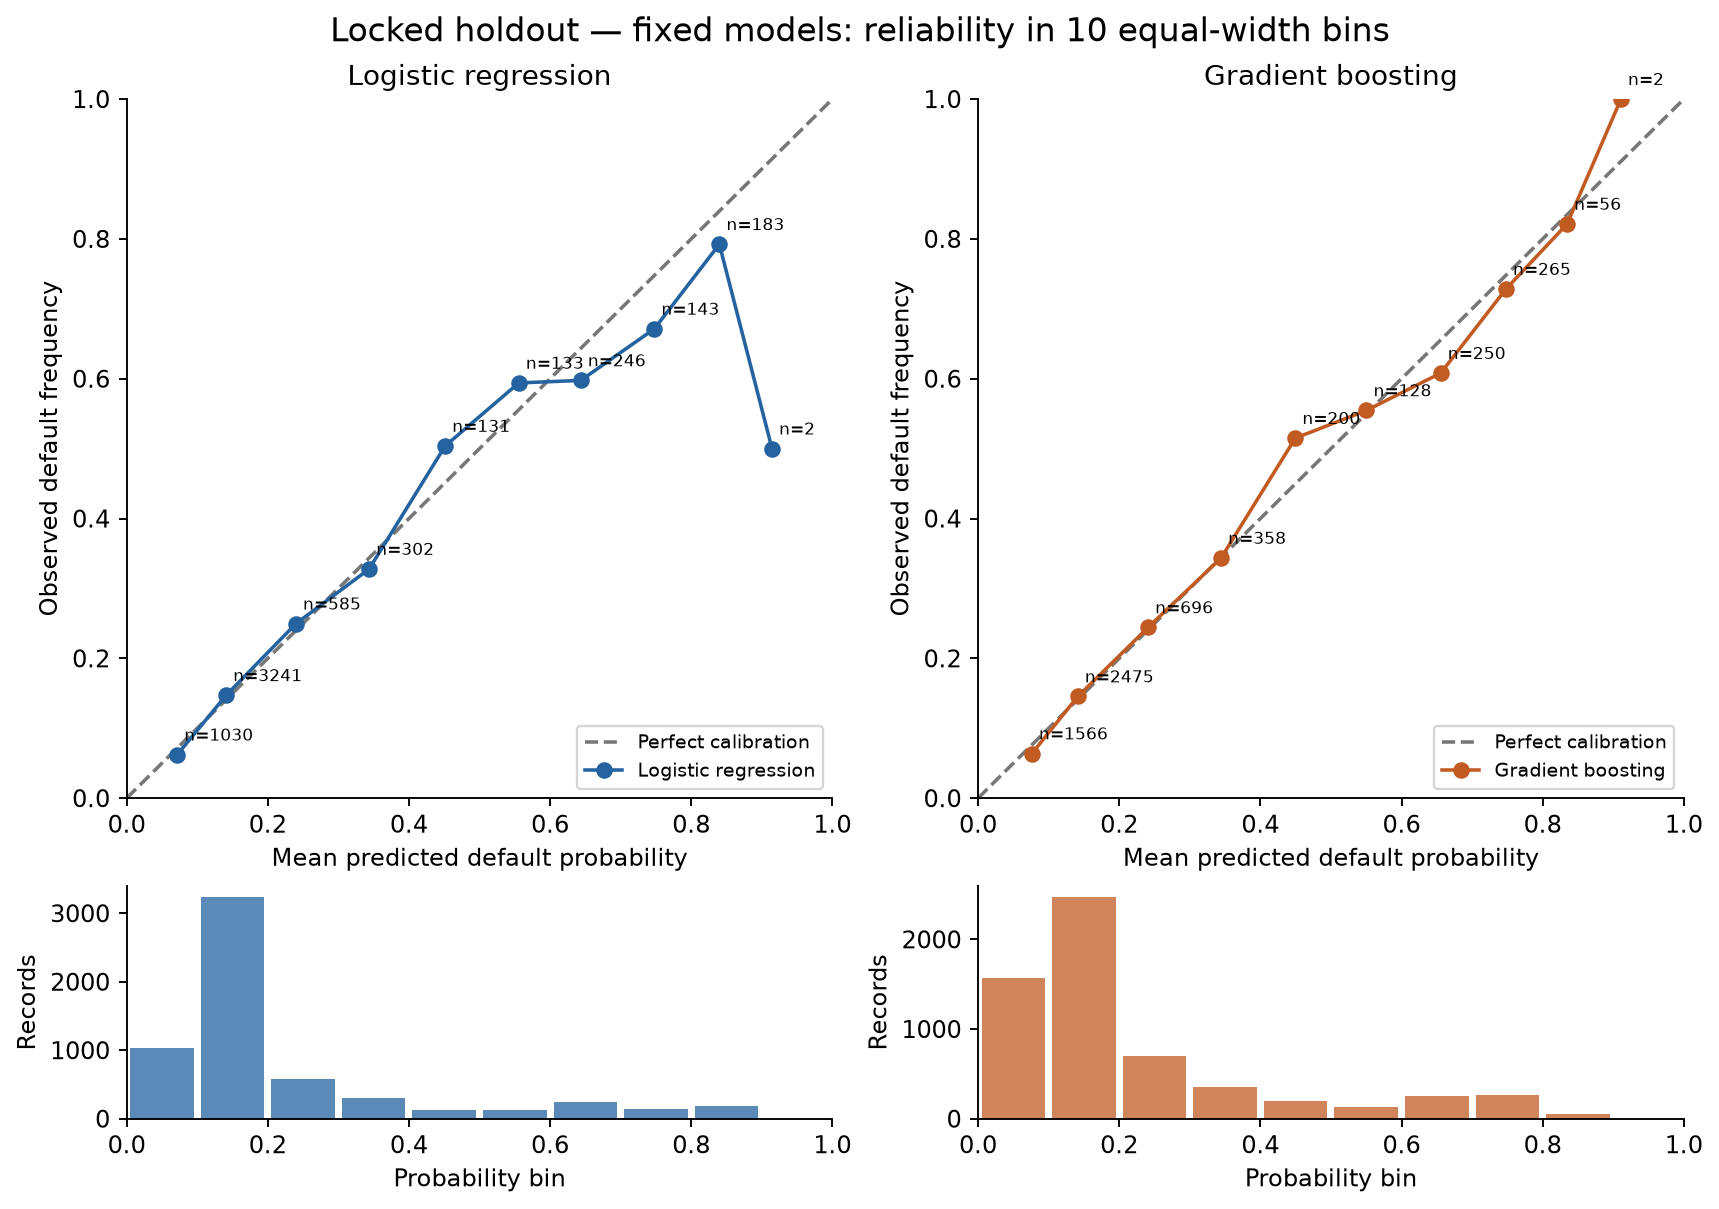

In [6]:
holdout = read_table("holdout_metrics")
display(holdout[["model", "threshold", "records", "TN", "FP", "FN", "TP", *METRICS]])
display(read_table("overall_performance_comparison"))
display(Image(filename=str(FIGURE_DIR / "calibration_locked_holdout.png")))


## Group-bootstrap 95% confidence intervals

Use 2,000 attempts and default_rng(42). Resample the number of distinct holdout
predictor groups with replacement; a selected group's entire set of records is
included, repeated together when drawn again. Integer group multiplicities are
used as per-row sample weights. Sample record counts can vary with group sizes.
Intervals use the 2.5th and 97.5th percentiles, linear quantile interpolation.

The two fixed models share resamples; no paired difference test, difference CI,
p-value or significance conclusion is implemented. Samples lacking either outcome
class are skipped and counted (none occurred here). These intervals condition on
the fitted models and observed holdout, excluding retraining and future-shift
uncertainty.

In [7]:
intervals = read_table("holdout_confidence_intervals")
display(intervals[["model", "metric", "estimate", "ci_lower", "ci_upper", "valid_repetitions"]])
replicates = read_table("holdout_bootstrap_replicates")
display(replicates.groupby("model").sample_records.agg(["min", "mean", "max"]))
assert intervals.valid_repetitions.eq(2000).all()
assert intervals.single_class_samples_skipped.eq(0).all()


,model,metric,estimate,ci_lower,ci_upper,valid_repetitions
0,logistic,ROC-AUC,0.756949,0.741230,0.771889,2000
1,logistic,Average Precision (AP),0.527009,0.498211,0.557173,2000
2,logistic,Accuracy,0.818045,0.807863,0.827724,2000
3,logistic,Balanced Accuracy,0.651717,0.638061,0.664976,2000
4,logistic,Precision,0.661952,0.625875,0.696662,2000
5,logistic,Recall,0.354545,0.327340,0.380512,2000
6,logistic,Specificity,0.948888,0.942353,0.955117,2000
7,logistic,F1,0.461766,0.433315,0.488373,2000
8,logistic,Log Loss,0.440924,0.426386,0.456093,2000
9,logistic,Brier Score,0.138169,0.132479,0.144041,2000


,min,mean,max
model,,,
gradient_boosting,5982,5996.0285,6012
logistic,5982,5996.0285,6012


## Findings, limitations and remaining decisions

- Boosting's ROC-AUC/AP advantage is consistent across folds. It also has lower
  probability losses, but neither model dominates every performance dimension.
  Holdout classification at 0.50 remains close, with recall around 35%.
- This is one five-fold assignment; fold training sets overlap. Pooled OOF metrics
  need not equal fold means, and CV models train on less data than saved baselines.
- Exact-group separation does not prove independence of all observations. The
  holdout's earlier inspection stays disclosed. CIs are conditional, not a model
  superiority test.
- Candidate thresholds are characterized using their source OOF predictions.
  Before selecting one, agree costs/recall constraints/acceptable false-positive
  workload, whether a common threshold or common operating criterion is appropriate,
  and a training-only confirmation or nested-validation method.
- Decide separately whether any training-only calibration experiment is needed.
  No new threshold, calibrator or model was selected. Fairness and later research
  stages have not begun.

See [the Performance Evaluation report](../outputs/performance_evaluation_report.md)
for the full findings, output inventory and reproducible protocol.